In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uncertainties

In [2]:
df = pd.read_csv("run_25K.csv")
df.head()

,V_Copper,V_Sapphire,time,sensor_temperature,temperature_setpoint,iTC_P_param,iTC_I_param,iTC_D_param
0,-0.000006,-5.819088e-07,0.000000,25.0266,25.0,2.0,1.0,0.0
1,-0.000006,-6.585442e-07,0.249738,25.0196,25.0,2.0,1.0,0.0
2,-0.000006,-1.049854e-06,0.499743,25.0055,25.0,2.0,1.0,0.0
3,-0.000006,-8.420171e-07,0.760804,24.9976,25.0,2.0,1.0,0.0
4,-0.000006,-5.603951e-07,0.995330,24.9938,25.0,2.0,1.0,0.0


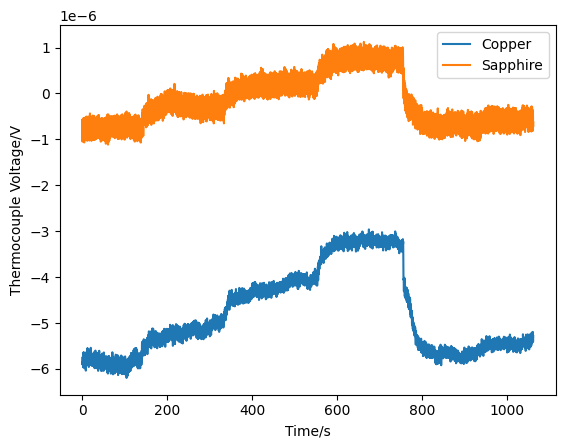

In [3]:
time = df['time']
v_cop = df['V_Copper']
v_sap = df['V_Sapphire']

plt.plot(time, v_cop, label = 'Copper')
plt.plot(time, v_sap, label = 'Sapphire')
plt.legend()
plt.xlabel("Time/s")
plt.ylabel("Thermocouple Voltage/V")
plt.show()

In [4]:
windows15K = {
    "V_Copper":   [(0, 118), (155, 228), (260, 395), (440, 612), (660, 770)],
    "V_Sapphire": [(0, 118), (145, 228), (255, 395), (425, 612), (660, 770)],
}

windows20K = {
    "V_Copper":   [(0, 105), (175, 238), (285, 365), (420, 498), (630, 670)],
    "V_Sapphire": [(0, 105), (140, 238), (270, 365), (390, 498), (620, 670)],
}

windows30K = {
    "V_Copper":   [(0, 115), (200, 292), (340, 430), (500, 670), (725, 855)],
    "V_Sapphire": [(0, 115), (190, 292), (330, 430), (500, 670), (725, 855)],
}

windows40K = {
    "V_Copper":   [(0, 110), (175, 262), (320, 415), (520, 715), (800, 970)],
    "V_Sapphire": [(0, 110), (170, 255), (300, 450), (510, 715), (860, 970)],
}

windows25K = {
    "V_Copper":   [(0, 115), (225, 325), (450, 548), (600, 745), (800, 915)],
    "V_Sapphire": [(0, 115), (215, 330), (375, 550), (600, 745), (800, 915)],
}

windows = windows25K

v_avg = {}
v_std = {}

for material, times in windows.items():
    print(material)
    v_avg[material] = []
    v_std[material] = []
    for start, end in times:
        in_window = (time >= start) & (time <= end)
        average = df.loc[in_window, material].mean()
        std = df.loc[in_window, material].std()
        v_avg[material].append(average)
        v_std[material].append(std)
        print(f"  {start}-{end} s: {average:.4e} +- {std:.4e} V")

V_Copper
  0-115 s: -5.8567e-06 +- 1.2232e-07 V
  225-325 s: -5.1314e-06 +- 1.2272e-07 V
  450-548 s: -4.1166e-06 +- 1.1363e-07 V
  600-745 s: -3.2256e-06 +- 9.0948e-08 V
  800-915 s: -5.6734e-06 +- 1.0099e-07 V
V_Sapphire
  0-115 s: -7.3568e-07 +- 1.8402e-07 V
  215-330 s: -2.7710e-07 +- 1.8137e-07 V
  375-550 s: 1.8583e-07 +- 1.7500e-07 V
  600-745 s: 7.4764e-07 +- 1.7074e-07 V
  800-915 s: -6.8531e-07 +- 1.6619e-07 V


In [5]:
baseline = {
    "V_Copper": v_avg["V_Copper"][0],
    "V_Sapphire": v_avg["V_Sapphire"][0]
}

v_avg_adj = {}

for material in v_avg.keys():
    v_avg_adj[material] = []
    #print(material)
    for i in range(1, len(v_avg[material])-1):
        v_avg_adj[material].append(v_avg[material][i]-baseline[material])
for material, values in v_avg_adj.items():
    print(material)
    output = "[0,"
    std_output = f"[{v_std[material][0]},"
    for i, v in enumerate(values, start=1):
        #print(f"  Step {i}: {v:.4e} V")
        output = output + f"{v}"
        std_output = std_output + f"{v_std[material][i-1]}"
        if i != len(values):
            output = output+","
            std_output = std_output+","
    output = output + "]"
    std_output = std_output + "]"
    print(output)
    print(std_output)



V_Copper
[0,7.252233194668988e-07,1.740029509207161e-06,2.6310781511775357e-06]
[1.2232413823107136e-07,1.2232413823107136e-07,1.2271733595043388e-07,1.1362887670474611e-07]
V_Sapphire
[0,4.5858533636348397e-07,9.215143428462773e-07,1.4833239386775362e-06]
[1.8401694852848212e-07,1.8401694852848212e-07,1.8136795735690336e-07,1.7499528707800892e-07]


In [6]:
# --- Baseline-drift correction: straight line between the two baselines ---
v_avg_drift = {}

for material, times in windows.items():
    # midpoint times of every window
    t_mid = [(start + end) / 2 for start, end in times]

    # straight line through (t_first, V_first) and (t_last, V_last)
    t0, t1 = t_mid[0], t_mid[-1]
    v0, v1 = v_avg[material][0], v_avg[material][-1]
    gradient = (v1 - v0) / (t1 - t0)

    def baseline_line(t):
        return v0 + gradient * (t - t0)

    # subtract the line's value at each intermediate step's midpoint
    v_avg_drift[material] = [0]
    for i in range(1, len(times) - 1):
        v_avg_drift[material].append(float(v_avg[material][i] - baseline_line(t_mid[i])))

for material, values in v_avg_drift.items():
    print(material)
    output = "[" + ",".join(f"{v}" for v in values) + "]"
    std_output = "[" + ",".join(f"{v_std[material][i]}" for i in range(len(values))) + "]"
    print(output)
    print(std_output)

V_Copper
[0,6.753907239539173e-07,1.6388750682003498e-06,2.490172191451173e-06]
[1.2232413823107136e-07,1.2271733595043388e-07,1.1362887670474611e-07,9.094800512614874e-08]
V_Sapphire
[0,4.45046953045122e-07,8.960118068279675e-07,1.4445978654645475e-06]
[1.8401694852848212e-07,1.8136795735690336e-07,1.7499528707800892e-07,1.7074103056780301e-07]
